In [1]:
import pandas as pd
import numpy as np

DATA_PATH = "../data/processed/eduassist_ml_dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (21444, 30)


,id_student,code_module,code_presentation,first_score,second_score,early_avg_score,early_min_score,early_max_score,early_assessment_count,second_assessment_date,...,num_of_prev_attempts,studied_credits,disability,clicks_before_cutoff,active_days_before_cutoff,unique_resources_before_cutoff,vle_records_before_cutoff,average_daily_clicks_before_cutoff,future_performance_category,future_risk_level
0,6516,AAA,2014J,60.0,48.0,54.0,48.0,60.0,2,54.0,...,0,60,N,1001.0,44.0,42.0,209.0,22.750000,Good,Low
1,8462,DDD,2013J,93.0,83.0,88.0,83.0,93.0,2,53.0,...,0,90,N,516.0,35.0,90.0,219.0,14.742857,Excellent,Low
2,8462,DDD,2014J,93.0,83.0,88.0,83.0,93.0,2,41.0,...,1,60,N,10.0,1.0,3.0,4.0,10.000000,Excellent,Low
3,11391,AAA,2013J,78.0,85.0,81.5,78.0,85.0,2,54.0,...,0,240,N,529.0,18.0,33.0,90.0,29.388889,Excellent,Low
4,23629,BBB,2013B,67.0,63.0,65.0,63.0,67.0,2,47.0,...,2,60,N,61.0,7.0,7.0,24.0,8.714286,Excellent,Low


In [2]:
# Target variable
TARGET = "future_average_score"

# Columns that must NOT be used as ML inputs
DROP_COLUMNS = [
    "id_student",
    "future_average_score",
    "future_min_score",
    "future_max_score",
    "future_assessment_count",
    "future_performance_category",
    "future_risk_level"
]

X = df.drop(columns=DROP_COLUMNS)
y = df[TARGET]

print("Input features:", X.shape)
print("Target:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget statistics:")
print(y.describe())

Input features: (21444, 23)
Target: (21444,)

Input features:
['code_module', 'code_presentation', 'first_score', 'second_score', 'early_avg_score', 'early_min_score', 'early_max_score', 'early_assessment_count', 'second_assessment_date', 'score_trend', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'disability', 'clicks_before_cutoff', 'active_days_before_cutoff', 'unique_resources_before_cutoff', 'vle_records_before_cutoff', 'average_daily_clicks_before_cutoff']

Target statistics:
count    21444.000000
mean        74.735842
std         15.921194
min          0.000000
25%         66.200000
50%         77.900000
75%         86.500000
max        100.000000
Name: future_average_score, dtype: float64


In [3]:
from sklearn.model_selection import GroupShuffleSplit

# Use student ID only for grouping
groups = df["id_student"]

# 80% training, 20% testing
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining target mean:", y_train.mean())
print("Testing target mean:", y_test.mean())

print("\nTraining students:", df.iloc[train_idx]["id_student"].nunique())
print("Testing students:", df.iloc[test_idx]["id_student"].nunique())

Training samples: 17156
Testing samples: 4288

Training target mean: 74.70894413188945
Testing target mean: 74.84346071825667

Training students: 15835
Testing students: 3959


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify feature types
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median"))
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("\nPreprocessor created successfully!")

Categorical features:
['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']

Numerical features:
['first_score', 'second_score', 'early_avg_score', 'early_min_score', 'early_max_score', 'early_assessment_count', 'second_assessment_date', 'score_trend', 'num_of_prev_attempts', 'studied_credits', 'clicks_before_cutoff', 'active_days_before_cutoff', 'unique_resources_before_cutoff', 'vle_records_before_cutoff', 'average_daily_clicks_before_cutoff']

Preprocessor created successfully!


C:\Users\PC\AppData\Local\Temp\ipykernel_16420\4143174983.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [5]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest model
model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Complete ML pipeline
ml_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

print("Training Random Forest model...")

ml_pipeline.fit(X_train, y_train)

print("Model training completed successfully!")

Training Random Forest model...
Model training completed successfully!


In [6]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict future performance
y_pred = ml_pipeline.predict(X_test)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=" * 60)
print("RANDOM FOREST MODEL EVALUATION")
print("=" * 60)

print(f"\nMAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

print("\nExample predictions:")
results = pd.DataFrame({
    "Actual Score": y_test.values[:10],
    "Predicted Score": y_pred[:10]
})

print(results.to_string(index=False))

RANDOM FOREST MODEL EVALUATION

MAE  : 8.30
RMSE : 11.13
R²   : 0.4851

Example predictions:
 Actual Score  Predicted Score
    67.000000        55.555930
   100.000000        78.485358
    63.333333        81.006135
    94.166667        81.562222
    29.000000        40.924165
    48.000000        64.341232
    87.166667        73.692122
    82.500000        77.186933
    88.000000        80.789659
    87.500000        81.982507


In [7]:
def get_risk_level(score):
    if score < 50:
        return "High"
    elif score < 65:
        return "Medium"
    else:
        return "Low"


# Convert predicted scores into risk levels
predicted_risk = pd.Series(y_pred).apply(get_risk_level)

# Actual risk levels
actual_risk = y_test.apply(get_risk_level).reset_index(drop=True)

print("=" * 60)
print("RISK LEVEL DISTRIBUTION")
print("=" * 60)

print("\nActual:")
print(actual_risk.value_counts())

print("\nPredicted:")
print(predicted_risk.value_counts())

RISK LEVEL DISTRIBUTION

Actual:
future_average_score
Low       3313
Medium     663
High       312
Name: count, dtype: int64

Predicted:
Low       3449
Medium     692
High       147
Name: count, dtype: int64


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Convert actual and predicted scores into risk levels
actual_risk = y_test.reset_index(drop=True).apply(get_risk_level)
predicted_risk = pd.Series(y_pred).apply(get_risk_level)

# Classification metrics
accuracy = accuracy_score(actual_risk, predicted_risk)

precision = precision_score(
    actual_risk,
    predicted_risk,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    actual_risk,
    predicted_risk,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    actual_risk,
    predicted_risk,
    average="weighted",
    zero_division=0
)

print("=" * 60)
print("RISK CLASSIFICATION PERFORMANCE")
print("=" * 60)

print(f"\nAccuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        actual_risk,
        predicted_risk,
        labels=["High", "Medium", "Low"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
cm = confusion_matrix(
    actual_risk,
    predicted_risk,
    labels=["High", "Medium", "Low"]
)

print(
    pd.DataFrame(
        cm,
        index=["Actual High", "Actual Medium", "Actual Low"],
        columns=["Predicted High", "Predicted Medium", "Predicted Low"]
    )
)

RISK CLASSIFICATION PERFORMANCE

Accuracy : 0.7929
Precision: 0.7848
Recall   : 0.7929
F1-Score : 0.7845

Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.59      0.28      0.37       312
      Medium       0.40      0.42      0.41       663
         Low       0.88      0.92      0.90      3313

    accuracy                           0.79      4288
   macro avg       0.62      0.54      0.56      4288
weighted avg       0.78      0.79      0.78      4288


Confusion Matrix:
               Predicted High  Predicted Medium  Predicted Low
Actual High                86               154             72
Actual Medium              44               278            341
Actual Low                 17               260           3036


In [10]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Gradient Boosting model
gradient_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.05,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

gradient_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", gradient_model)
    ]
)

print("Training Gradient Boosting model...")

gradient_pipeline.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Training Gradient Boosting model...
Gradient Boosting training completed!


In [11]:
# Predict on the same test set
y_pred_gb = gradient_pipeline.predict(X_test)

# Calculate regression metrics
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("=" * 60)
print("GRADIENT BOOSTING PERFORMANCE")
print("=" * 60)

print(f"\nMAE  : {mae_gb:.4f}")
print(f"RMSE : {rmse_gb:.4f}")
print(f"R²   : {r2_gb:.4f}")

print("\nSample Predictions:")
comparison_gb = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True).head(10),
    "Predicted": y_pred_gb[:10]
})

print(comparison_gb)

GRADIENT BOOSTING PERFORMANCE

MAE  : 8.1575
RMSE : 10.9438
R²   : 0.5024

Sample Predictions:
       Actual  Predicted
0   67.000000  56.435352
1  100.000000  78.284362
2   63.333333  80.684168
3   94.166667  83.149295
4   29.000000  45.953870
5   48.000000  64.613373
6   87.166667  75.289832
7   82.500000  80.258419
8   88.000000  82.926750
9   87.500000  80.849510


In [12]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

MODEL_PATH = MODEL_DIR / "gradient_boosting_performance_model.pkl"

joblib.dump(gradient_pipeline, MODEL_PATH)

print("Model saved successfully!")
print("Path:", MODEL_PATH)

Model saved successfully!
Path: ..\models\gradient_boosting_performance_model.pkl


In [13]:
import joblib

loaded_model = joblib.load(MODEL_PATH)

test_predictions = loaded_model.predict(X_test.head(5))

print("Saved model loaded successfully!")
print("\nTest predictions:")
print(test_predictions)

Saved model loaded successfully!

Test predictions:
[56.4353515  78.28436165 80.68416792 83.14929499 45.9538701 ]


In [15]:
from sklearn.inspection import permutation_importance

print("Calculating feature importance...")

perm_importance = permutation_importance(
    gradient_pipeline,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

feature_importance_gb = pd.DataFrame({
    "feature": X_test.columns,
    "importance": perm_importance.importances_mean
}).sort_values("importance", ascending=False)

print("=" * 60)
print("GRADIENT BOOSTING - TOP 20 FEATURES")
print("=" * 60)

print(feature_importance_gb.head(20).to_string(index=False))

Calculating feature importance...
GRADIENT BOOSTING - TOP 20 FEATURES
                       feature  importance
                   code_module    2.788560
                  second_score    1.087173
               early_min_score    0.663231
        second_assessment_date    0.461060
               early_max_score    0.231803
               early_avg_score    0.201391
unique_resources_before_cutoff    0.144353
             highest_education    0.094757
             code_presentation    0.074989
                   first_score    0.057230
          clicks_before_cutoff    0.045075
     vle_records_before_cutoff    0.035884
     active_days_before_cutoff    0.023650
                      age_band    0.023113
                        region    0.021039
               studied_credits    0.019133
                   score_trend    0.017361
                      imd_band    0.015188
                        gender    0.005896
                    disability    0.004667


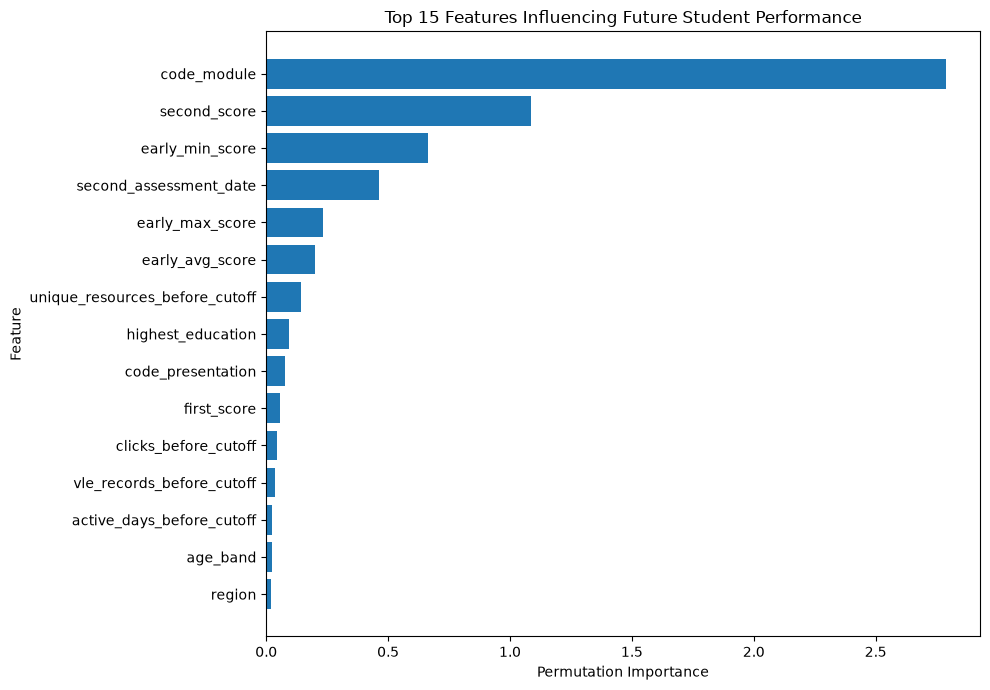

In [16]:
import matplotlib.pyplot as plt

top_features = feature_importance_gb.head(15).sort_values("importance")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Future Student Performance")

plt.tight_layout()
plt.show()

In [17]:
model_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae,
        mae_gb
    ],
    "RMSE": [
        rmse,
        rmse_gb
    ],
    "R2": [
        r2,
        r2_gb
    ]
})

print("=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

print(model_comparison.to_string(index=False))

MODEL COMPARISON
            Model      MAE      RMSE       R2
    Random Forest 8.296505 11.132473 0.485126
Gradient Boosting 8.157549 10.943799 0.502431


In [18]:
# Save model comparison results

RESULTS_PATH = "../data/processed/model_comparison.csv"

model_comparison.to_csv(RESULTS_PATH, index=False)

print("Model comparison saved successfully!")
print("Path:", RESULTS_PATH)

Model comparison saved successfully!
Path: ../data/processed/model_comparison.csv


In [19]:
print("=" * 60)
print("FUTURE RISK LEVEL DISTRIBUTION")
print("=" * 60)

risk_distribution = df["future_risk_level"].value_counts()

print(risk_distribution)

print("\nPercentage Distribution:")
print(
    (df["future_risk_level"].value_counts(normalize=True) * 100)
    .round(2)
)

FUTURE RISK LEVEL DISTRIBUTION
future_risk_level
Low       16547
Medium     3199
High       1698
Name: count, dtype: int64

Percentage Distribution:
future_risk_level
Low       77.16
Medium    14.92
High       7.92
Name: proportion, dtype: float64


In [20]:
from sklearn.model_selection import GroupShuffleSplit

RISK_TARGET = "future_risk_level"

X_risk = df.drop(columns=[
    "id_student",
    "future_average_score",
    "future_min_score",
    "future_max_score",
    "future_assessment_count",
    "future_performance_category",
    "future_risk_level"
])

y_risk = df[RISK_TARGET]

groups_risk = df["id_student"]

risk_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

risk_train_idx, risk_test_idx = next(
    risk_splitter.split(X_risk, y_risk, groups=groups_risk)
)

X_risk_train = X_risk.iloc[risk_train_idx].copy()
X_risk_test = X_risk.iloc[risk_test_idx].copy()

y_risk_train = y_risk.iloc[risk_train_idx].copy()
y_risk_test = y_risk.iloc[risk_test_idx].copy()

print("Risk classification dataset prepared!")
print("Training samples:", len(X_risk_train))
print("Testing samples:", len(X_risk_test))

print("\nTraining risk distribution:")
print(y_risk_train.value_counts())

print("\nTesting risk distribution:")
print(y_risk_test.value_counts())

Risk classification dataset prepared!
Training samples: 17156
Testing samples: 4288

Training risk distribution:
future_risk_level
Low       13234
Medium     2536
High       1386
Name: count, dtype: int64

Testing risk distribution:
future_risk_level
Low       3313
Medium     663
High       312
Name: count, dtype: int64


In [21]:
from sklearn.ensemble import RandomForestClassifier

risk_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

risk_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", risk_model)
    ]
)

print("Training Risk Classification model...")

risk_pipeline.fit(X_risk_train, y_risk_train)

print("Risk Classification model training completed!")

Training Risk Classification model...
Risk Classification model training completed!


In [22]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y_risk_pred = risk_pipeline.predict(X_risk_test)

print("=" * 60)
print("RISK CLASSIFICATION MODEL EVALUATION")
print("=" * 60)

print(f"\nAccuracy: {accuracy_score(y_risk_test, y_risk_pred):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_risk_test,
        y_risk_pred,
        labels=["High", "Medium", "Low"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
cm_risk = confusion_matrix(
    y_risk_test,
    y_risk_pred,
    labels=["High", "Medium", "Low"]
)

print(
    pd.DataFrame(
        cm_risk,
        index=["Actual High", "Actual Medium", "Actual Low"],
        columns=["Predicted High", "Predicted Medium", "Predicted Low"]
    )
)

RISK CLASSIFICATION MODEL EVALUATION

Accuracy: 0.7337

Classification Report:
              precision    recall  f1-score   support

        High       0.40      0.53      0.46       312
      Medium       0.32      0.48      0.38       663
         Low       0.92      0.80      0.86      3313

    accuracy                           0.73      4288
   macro avg       0.55      0.60      0.57      4288
weighted avg       0.79      0.73      0.76      4288


Confusion Matrix:
               Predicted High  Predicted Medium  Predicted Low
Actual High               166               116             30
Actual Medium             148               315            200
Actual Low                 96               552           2665


In [23]:
RISK_MODEL_PATH = MODEL_DIR / "risk_classification_model.pkl"

joblib.dump(risk_pipeline, RISK_MODEL_PATH)

print("Risk classification model saved successfully!")
print("Path:", RISK_MODEL_PATH)

Risk classification model saved successfully!
Path: ..\models\risk_classification_model.pkl
